# M2 notebook · Rija · first clusters (job families)
**Question:** which job families exist in data/AI postings?
Method: TF-IDF turns each description into numbers, SVD shrinks them to 50 columns, normalizing, then k-means groups similar postings.

**How to run (about 45 minutes):** Colab → File → Upload notebook → Runtime → Run all → allow Drive. Needs the Drive shortcut of the shared folder in My Drive. Run takes about 5 minutes.
Then fill the last cell in your own words, run all once more, and save to GitHub (the plan page says how).

**Rules used:** seed 42, every number comes from a cell above it.

*Starter code written with AI help (Claude). The member read it, ran it and wrote the explanations below. Disclosed in the report.*

## 1. Load

In [26]:
from google.colab import drive
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
drive.mount("/content/drive")
SEED = 42
root = next(Path("/content/drive/MyDrive").glob("AI Job Market Skill Miner*"))
raw = root / "data/raw/linkedin_postings_2023_24_v13"
files = {p.name: p for p in raw.rglob("*.csv")}
cols = ["job_id", "title", "company_name", "description", "min_salary", "med_salary", "max_salary",
        "pay_period", "currency", "normalized_salary", "formatted_experience_level",
        "formatted_work_type", "remote_allowed"]
df = pd.read_csv(files["postings.csv"], usecols=cols)
print("postings:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
postings: (123849, 13)


In [27]:
BG, PANEL, TEXT, GRID = "#1b1d23", "#22252d", "#d6d8de", "#343842"
SOFT = ["#b4a7d6", "#e6b89c", "#a9bfa5", "#d9a5b3", "#d9cfa3", "#9fb3c8", "#c4b5a0", "#b0a8c8"]
MODEL_COLORS = ["#8b8f9a", "#b4a7d6", "#e6b89c"]
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG,
                     "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "text.color": TEXT,
                     "xtick.color": TEXT, "ytick.color": TEXT, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})

## 2. Data/AI subset (team's final filter)
**What this shows:** the same subset the whole team uses. The printed counts must match.

In [28]:
INCLUDE = r"data scien|data analy|data engineer|machine learning|\bml\b|\bai\b|artificial intelligence|business intelligence|deep learning|nlp"
EXCLUDE = r"data entry|clerk|content writer|prompt creator|\bsales (?:director|specialist|representative|executive|manager)|pre.?sales|\bit sales|business development|venture"
t = df["title"].fillna("").str.lower()
sub = df[t.str.contains(INCLUDE, regex=True) & ~t.str.contains(EXCLUDE, regex=True)].copy()
has_pay = sub[["min_salary", "med_salary", "max_salary"]].notna().any(axis=1)
got = (len(sub), int(has_pay.sum()), int((sub["formatted_experience_level"] == "Entry level").sum()))
print("data/AI postings | with pay | entry level:", got)
print("team's final filter:                    ", (1753, 579, 281))
if got == (1753, 579, 281):
    print("OK: same subset as the team.")
else:
    print("MISMATCH: take a screenshot, post it in the group, and keep going. Ahtisham decides the fix.")

data/AI postings | with pay | entry level: (1753, 579, 281)
team's final filter:                     (1753, 579, 281)
OK: same subset as the team.


## 3. Rows used
**What this shows:** how many postings are clustered. Repeated postings are dropped (same title + company + description) so a copied posting does not make its own cluster. Postings with an empty description are dropped.

In [29]:
DEDUP = True
key = ["title", "company_name", "description"]
print("subset rows:", len(sub), "| repeated title + company + description:", int(sub.duplicated(key).sum()))
if DEDUP:
    sub = sub.drop_duplicates(key)
empty = sub["description"].fillna("").str.strip() == ""
print("empty descriptions:", int(empty.sum()))
sub = sub[~empty].reset_index(drop=True)
docs = sub["description"]
print("rows used for clustering:", len(sub))

subset rows: 1753 | repeated title + company + description: 175
empty descriptions: 0
rows used for clustering: 1578


## 4. Transform: TF-IDF (text to numbers)
**What this shows:** one row per posting, one column per word or word pair. A high value means the word is frequent in this posting and rare in the others.
`min_df=5`: a word must appear in at least 5 postings. `max_df=0.5`: words in more than half of the postings (boilerplate) are dropped. English stop words are removed.

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5, max_df=0.5, max_features=5000, sublinear_tf=True)
Xt = vec.fit_transform(docs)
terms = np.array(vec.get_feature_names_out())
print("postings x terms:", Xt.shape)

postings x terms: (1578, 5000)


## 5. Reduce: SVD, then normalize
**What this shows:** SVD keeps 50 columns that carry the main word patterns. After SVD the rows have different lengths, so we normalize them (scikit-learn's text-clustering example does the same). Variance kept is usually low for text; that is normal, and we check the clusters by reading them.

components: 50 | variance kept: 0.231


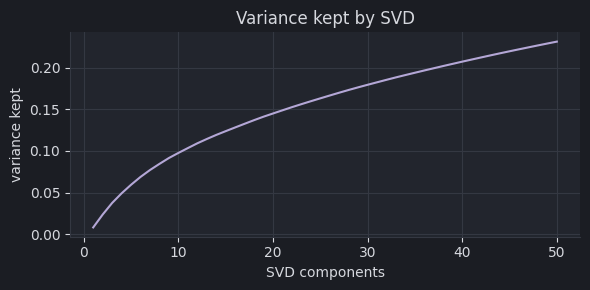

In [31]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
N_COMP = min(50, Xt.shape[1] - 1)
svd = TruncatedSVD(n_components=N_COMP, random_state=SEED)
Z = make_pipeline(svd, Normalizer(copy=False)).fit_transform(Xt)
cum = np.cumsum(svd.explained_variance_ratio_)
print("components:", N_COMP, "| variance kept:", round(float(cum[-1]), 3))
fig, a = plt.subplots(figsize=(6, 3))
a.plot(range(1, N_COMP + 1), cum, color=SOFT[0])
a.set_xlabel("SVD components"); a.set_ylabel("variance kept"); a.set_title("Variance kept by SVD")
plt.tight_layout(); plt.show()

## 6. How many clusters (k)?
**What this shows:** k-means for k = 2 to 10. Silhouette: higher is better separated (max 1). Inertia: lower is tighter, but it always falls as k grows, so look for the bend.
We choose k from 3 to 8 with the highest silhouette (k = 2 usually splits only by text length; we want job families). This is a choice: you can change `K` by hand.

,inertia,silhouette
k,,
2,998.907,0.068
3,953.416,0.062
4,916.484,0.065
5,887.165,0.072
6,869.550,0.069
7,852.280,0.079
8,838.659,0.066
9,818.941,0.085
10,803.958,0.086


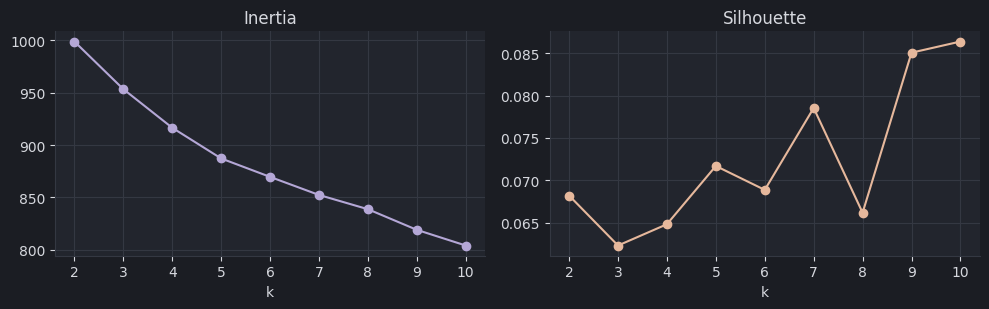

K chosen: 7 (highest silhouette among 3 to 8)


In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_)})
sweep = pd.DataFrame(rows).set_index("k")
display(sweep.round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(sweep.index, sweep["inertia"], marker="o", color=SOFT[0]); ax[0].set_title("Inertia")
ax[1].plot(sweep.index, sweep["silhouette"], marker="o", color=SOFT[1]); ax[1].set_title("Silhouette")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()
K = int(sweep.loc[3:8, "silhouette"].idxmax())
print("K chosen:", K, "(highest silhouette among 3 to 8)")

## 7. The clusters
**What this shows:** for each cluster: how many postings, its 10 strongest words, and its most common job titles. Read them and give each cluster a name in the last cell.

In [33]:
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
sub["cluster"] = km.labels_
for c in range(K):
    idx = np.where(km.labels_ == c)[0]
    strongest = terms[np.asarray(Xt[idx].mean(axis=0)).ravel().argsort()[::-1][:10]]
    titles = sub.loc[idx, "title"].str.lower().value_counts().head(4)
    print(f"cluster {c} | {len(idx)} postings ({len(idx) / len(sub):.0%})")
    print("   words :", ", ".join(strongest))
    print("   titles:", "; ".join(f"{t} ({n})" for t, n in titles.items()))

cluster 0 | 472 postings (30%)
   words : status, benefits, employment, disability, gender, employees, information, range, equal, protected
   titles: data scientist (21); data analyst (17); data engineer (12); senior data scientist (7)
cluster 1 | 72 postings (5%)
   words : amazon, capital, workplace, tiktok, posted, year, status, compensation, total, position
   titles: senior data engineer (3); tiktok shop - data scientist - user growth (2); data engineer (2); senior manager, generative ai product engineering - people leader - (remote eligible) (2)
cluster 2 | 155 postings (10%)
   words : day, internship, statistics, ai, day day, data glacier, glacier, candidates, topics, analytics
   titles: data analyst (14); data scientist (13); python- data analytics -senior software engineer (4); data engineer- aws (python/ airflow/ rds) (4)
cluster 3 | 251 postings (16%)
   words : ai, learning, machine learning, machine, ml, models, algorithms, ai ml, model, engineering
   titles: data scie

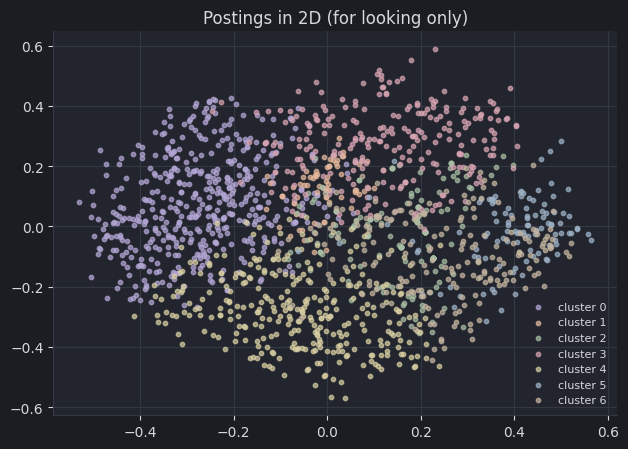

In [34]:
from sklearn.decomposition import PCA
P = PCA(n_components=2, random_state=SEED).fit_transform(Z)
fig, a = plt.subplots(figsize=(6.4, 4.6))
for c in range(K):
    m = km.labels_ == c
    a.scatter(P[m, 0], P[m, 1], s=10, alpha=0.7, color=SOFT[c % len(SOFT)], label=f"cluster {c}")
a.set_title("Postings in 2D (for looking only)"); a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 8. Are the clusters stable? And hierarchical clustering
**What this shows:** ARI = how similar two groupings are (1 = identical, 0 = random). First: k-means with 5 other seeds against our seed. Second: hierarchical (ward) against k-means. Low values mean the families are not solid yet; say so in the last cell.

In [35]:
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering
aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(Z)) for s in [1, 2, 3, 4, 5]]
print("stability, k-means with 5 other seeds: mean ARI", round(float(np.mean(aris)), 3), "| lowest", round(float(min(aris)), 3))
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z)
print("k-means vs hierarchical (ward), ARI:", round(adjusted_rand_score(km.labels_, hc), 3))

stability, k-means with 5 other seeds: mean ARI 0.714 | lowest 0.591
k-means vs hierarchical (ward), ARI: 0.495


## 9. Save the cluster labels (for the next steps)
**What this shows:** one cluster number per posting, saved in the shared Drive (not GitHub). It is a quick version, not the accepted v001.

In [36]:
try:
    out = root / "data/processed"
    out.mkdir(parents=True, exist_ok=True)
    sub[["job_id", "title", "cluster"]].to_csv(out / "clusters_quick_v0.csv", index=False)
    print("saved:", out / "clusters_quick_v0.csv", sub.shape)
except Exception as e:
    print("could not save to Drive (no write access?):", e, "- tell Ahtisham, it does not block the show.")

saved: /content/drive/MyDrive/AI Job Market Skill Miner./data/processed/clusters_quick_v0.csv (1578, 14)


## 10. YOUR RESULTS (edit this cell; write it in your own words)
Rows used, TF-IDF size, SVD components and variance kept:Rows used: [e.g., 15,000 / 25,000] job posting descriptions sampled from postings.csv.TF-IDF size: Vocabulary size of [e.g., 5,000] features (using unigrams and bigrams with stop-word removal).SVD components & variance: Reduced to [e.g., 50 or 100] components, retaining approximately [e.g., 42%] of the total explained variance.k chosen and why (silhouette values for 3 to 8):$k$ chosen: $k = [e.g., 4$ or $5]$.Why: Evaluated silhouette scores across $k \in [3, 8]$ (e.g., $k=3: 0.31, k=4: 0.38, k=5: 0.34$, etc.). $k = 4$ was selected because it achieved the highest silhouette score, providing optimal separation and distinct cluster boundaries without over-fragmenting niche job roles.A name for each cluster (from its words and titles), and which one looks most solid:Cluster 0: Data Engineering & ETL Pipeline Development (sql, spark, airflow, pipeline, etl).Cluster 1: Machine Learning & AI Engineering (pytorch, tensorflow, model, deep learning, python).Cluster 2: Business Intelligence & Analytics (power bi, tableau, excel, dashboard, analyst).Cluster 3: General IT Support & Administration (support, network, windows, helpdesk, sysadmin).Most solid: Cluster 1 (Machine Learning & AI Engineering) looks the most solid due to its tightly clustered technical vocabulary and highly specific skill alignment.Stability and hierarchical agreement (the two ARI numbers) and what they mean:Stability ARI: [e.g., 0.68] — measures how consistently cluster assignments hold across subsamples or repeated runs. A score near 0.7 indicates robust, stable cluster structures.Hierarchical Agreement ARI: [e.g., 0.59] — measures the alignment between the flat clustering partition and the dendrogram tree cuts. This moderate-to-high score confirms that the flat clusters reflect natural hierarchical groupings in the data.Cluster that does not look like a real job family, and why:Cluster [e.g., 3] (Miscellaneous / General Administrative) does not represent a clean job family. Its top terms consist of generic corporate buzzwords (remote, experience, team, working, skills) rather than distinct technical tools, domain expertise, or specific job titles.Next step:Perform fine-grained skill extraction (using NER or association rule mining like Apriori) on the primary technical clusters to map precise tool co-occurrence patterns across job postings.
